# 🧮 11-01 · ARMA 与 ARIMA：经典统计预测

> 目标：把「统计时序预测」的引擎拆开。学完本篇你能——
> ① 手写 **AR 的 OLS 估计、MA 的网格估计、Yule-Walker 解 AR(2)**，并说清各自适用场景；
> ② 用 **ψ-权重** 推出 h 步预测误差方差 $\\sigma^2\\sum_{j<h}\\psi_j^2$，手算并画出预测区间扇形图；
> ③ 讲清 **SARIMA** 的季节差分与季节多项式记号，并和 statsmodels 对照拟合预测；
> ④ 推导 **AIC/BIC**（高斯似然 → $n\\ln(\\text{SSE}/n)+2k$），并跑 **ARIMAX** 外生变量模型。

> 📍 **主线位置**：前一篇《00 基础与平稳性》（差分/ACF/PACF/检验）→ 本篇《ARMA 与 ARIMA》（**回归 + 频率域**视角的模型族）→ 后一篇《02 指数平滑》（**状态递推**视角，轻量落地）。
> 本篇是"统计预测"的正统：Box-Jenkins 方法论（识别 → 估计 → 诊断 → 预测）。

> 🧩 **生活化类比**：AR = **用昨天温度预测今天**（过去的自己）；MA = **修正昨天的预测误差**（过去的失误）。把两个想法组合起来就是 ARMA——一边看历史值，一边修正误差。

## 核心概念

### (a) 🗂️ 一张图看懂 ARMA 家族

```mermaid
flowchart TB
    Node1["🧠 平稳序列（00 篇已差分好）"]
    Node2["AR(p)：看自己过去 p 期"]
    Node3["MA(q)：看过去 q 期误差"]
    Node4["ARMA(p,q)：两者结合"]
    Node5["ARIMA(p,d,q)：d 阶差分 + ARMA"]
    Node6["ACF/PACF 定阶"]
    Node7["AR-OLS / Yule-Walker / MA 网格"]
    Node8["ψ-权重预测区间"]
    Node9["SARIMA 季节版 + ARIMAX 外生变量"]
    Node1 --> Node2
    Node1 --> Node3
    Node2 --> Node4
    Node3 --> Node4
    Node4 --> Node5
    Node5 --> Node6
    Node6 --> Node7
    Node7 --> Node8
    Node8 --> Node9
```

### (b) 六件必须带走的事

- **AR(p)**：$y_t = c + \\sum_{i=1}^{p}\\phi_i y_{t-i} + \\epsilon_t$——看自己的历史。
- **MA(q)**：$y_t = \\mu + \\sum_{j=1}^{q}\\theta_j \\epsilon_{t-j} + \\epsilon_t$——看过去的误差。
- **ARMA(p,q)**：两者相加；**ARIMA(p,d,q)**：对 $d$ 阶差分后的序列做 ARMA。

### (c) 三个必须带走的方法

- **平稳/可逆**：$|\\phi|<1$（或特征根在单位圆外）；MA 可逆 $|\\theta|<1$。
- **定阶**：AR→PACF 截尾；MA→ACF 截尾；或用 AIC/BIC 网格扫。
- **预测区间**：h 步误差方差 $\\sigma^2\\sum_{j<h}\\psi_j^2$，"越远越不确定"有定量表达。

## 0. 主线地图

```
平稳序列（00 篇终点）
   │
   ▼
ACF/PACF 定阶（拖尾/截尾 或 AIC/BIC 网格）
   │
   ▼
估计：AR→OLS / Yule-Walker；MA→网格；ARIMA→MLE
   │
   ▼
诊断：残差 Ljung-Box + 残差 ACF（须像白噪声）
   │
   ▼
预测：ψ-权重给出点预测 ± 预测区间
   │
   ▼
扩展：SARIMA（季节）+ ARIMAX（外生变量）
```

### 0.1 历史背景：Box-Jenkins 方法论

- **1970 年 Box & Jenkins**《Time Series Analysis: Forecasting and Control》：确立"识别 → 估计 → 诊断 → 预测"四步法，把 ARIMA 变成可操作的工业流程。
- **Wold 定理**（1938）：任何平稳序列可写成确定性部分 + MA(∞)；MA(∞) 又常能被有限阶 ARMA 近似——这给"为什么 ARMA 够用"提供了理论依据。
- **Yule（1927）与 Walker（1931）**：提出用自相关方程反解 AR 系数（Yule-Walker），比最小二乘更早、更优雅。
- **Akaike（1974）**：提出 AIC（赤池信息准则），把"拟合优度 + 模型复杂度"统一成一个可最小化的数。
- **一句话记忆**：**识别靠 ACF/PACF，估计靠 OLS/YW/MLE，诊断靠残差白噪声，预测靠 ψ-权重**——Box-Jenkins 四步走到底。

## 1. 模型定义：AR / MA / ARMA / ARIMA

| 模型 | 公式 | 参数 | 直觉 |
|---|---|---|---|
| AR(p) | $y_t = c + \\sum_{i=1}^p \\phi_i y_{t-i} + \\epsilon_t$ | $\\phi_1..\\phi_p$ | 看自己过去 |
| MA(q) | $y_t = \\mu + \\sum_{j=1}^q \\theta_j \\epsilon_{t-j} + \\epsilon_t$ | $\\theta_1..\\theta_q$ | 看过去误差 |
| ARMA(p,q) | 上面两者相加 | 两组参数 | 历史 + 误差修正 |
| ARIMA(p,d,q) | 对 $\\Delta^d y_t$ 做 ARMA | 含差分阶 d | 差分后建模 |

### 1.1 平稳/可逆条件

| 条件 | 含义 |
|---|---|
| $\\|\\phi\\|<1$（AR(1)）| 平稳：冲击影响指数衰减 |
| 特征根在单位圆外 | AR(p) 平稳的严格表述 |
| $\\|\\theta\\|<1$（MA(1)）| 可逆：MA 可改写回 AR(∞) |

> 面试一句话：**AR 平稳看系数，MA 永远平稳但可逆看 θ**；特征根单位圆外 = 冲击不会永久放大。

## 2. AR 的 OLS 估计（手写）

AR(p)：$y_t = c + \\sum_{i=1}^p \\phi_i y_{t-i} + \\epsilon_t$。写成矩阵：

$$\\mathbf{y} = \\mathbf{X}\\boldsymbol{\\phi} + \\boldsymbol{\\epsilon}, \\qquad \\mathbf{X} = [\\mathbf{1},\\ y_{t-1}, \\ldots, y_{t-p}]$$

OLS：$\\hat{\\boldsymbol{\\phi}} = (\\mathbf{X}^\\top\\mathbf{X})^{-1}\\mathbf{X}^\\top\\mathbf{y}$。

> 手算要点：**OLS = 分子"错位乘积和"，分母"滞后平方和"**——和 ACF 同源，只是不除以总方差。

### 2.1 手算 AR(1) 小例

设 $y=[2,4,3,5]$。先中心化（减去均值 3.5 → $[-1.5,0.5,-0.5,1.5]$）。

滞后矩阵 $X=[-1.5,0.5,-0.5]$，响应 $y'=[0.5,-0.5,1.5]$（错位对齐）。

$$\\hat\\phi = \\frac{\\sum X_t y'_{t+1}}{\\sum X_t^2} = \\frac{(-1.5)(0.5)+(0.5)(-0.5)+(-0.5)(1.5)}{2.25+0.25+0.25} = \\frac{-1.75}{2.75} \\approx -0.64$$

> 手算要点：**先中心化，再错位对齐做点积**——这样截距自动消失，只剩斜率估计。

## 3. Yule-Walker 方程组解 AR(2)（重点手算）

AR(2)：$y_t = \\phi_1 y_{t-1} + \\phi_2 y_{t-2} + \\epsilon_t$。两边乘 $y_{t-k}$ 取期望得：

$$\\gamma(k) = \\phi_1 \\gamma(k-1) + \\phi_2 \\gamma(k-2), \\qquad k\\ge 1$$

写成矩阵（Yule-Walker 方程）：

$$\\begin{pmatrix} \\gamma(0) & \\gamma(1) \\\\ \\gamma(1) & \\gamma(0) \\end{pmatrix}
\\begin{pmatrix} \\phi_1 \\\\ \\phi_2 \\end{pmatrix} =
\\begin{pmatrix} \\gamma(1) \\\\ \\gamma(2) \\end{pmatrix}$$


### 3.1 手算 2×2 例

设 $\\rho(1)=0.8,\\ \\rho(2)=0.5$（ACF 观测值）。方程化为：

$$0.8 = \\phi_1 + 0.5 \\phi_2 \\qquad 0.5 = 0.8\\phi_1 + \\phi_2$$

解得：$\\phi_1 = (0.8 - 0.4)/0.75 = 0.533$，$\\phi_2 = 0.5 - 0.8\\times 0.533 = 0.073$。

> 手算要点：**两个方程解两个未知数**；矩阵是 Toeplitz（对角相等），可用 Levinson-Durbin 递推加速。

## 4. MA 的网格估计（误差不可观测）

MA(q)：$y_t = \\mu + \\sum_{j=1}^q \\theta_j \\epsilon_{t-j} + \\epsilon_t$。问题：$\\epsilon_t$ **不可直接观测**——不能像 AR 那样构造矩阵。

**网格/数值优化思路**：给定参数 $\\theta$，用递推还原误差：

$$\\epsilon_t = y_t - \\mu - \\sum_{j=1}^q \\theta_j \\epsilon_{t-j}$$

然后最小化 $\\text{SSE} = \\sum_t \\epsilon_t^2$（或一步预测误差平方）。这就是**条件最小二乘**；统计软件多用 MLE（高斯似然）做同样的事。

> 面试一句话：**AR 能 OLS（误差可观），MA 必须迭代（误差不可观）**——网格/优化/滤波三选一。

### 4.1 为什么 MA 不能像 AR 那样 OLS？

AR 的 $y_{t-1}, y_{t-2}$ 是**观测到的**，直接进矩阵；MA 的 $\\epsilon_{t-1}, \\epsilon_{t-2}$ 是**隐含的**——只能靠递推一步步还原。

**还原递推**（条件最小二乘）：

$$\\epsilon_t = y_t - \\mu - \\sum_{j=1}^{q} \\theta_j \\epsilon_{t-j}$$

> 手算要点：给定 θ 就能从 $y$ 反推一串 $\\epsilon$，再算 SSE；**扫 θ → 还原 → 比 SSE** 就是网格估计。

## 5. AIC / BIC：从高斯似然到"拟合 + 惩罚"

**高斯似然**（残差 $\\epsilon_t \\sim N(0,\\sigma^2)$，$n$ 个样本）：

$$\\ln L = -\\frac{n}{2}\\ln(2\\pi\\sigma^2) - \\frac{1}{2\\sigma^2}\\sum_t \\epsilon_t^2$$

把 $\\sigma^2 \\approx \\text{SSE}/n$ 代入并整理（省去常数项）：

$$\\text{AIC} = -2\\ln L + 2k \\approx n\\ln\\left(\\frac{\\text{SSE}}{n}\\right) + 2k$$

其中 $k$ = 参数个数（AR(p)：$k=p+1$ 含截距）。BIC 把 $2k$ 换成 $k\\ln n$，对大样本惩罚更重。

### 5.1 手算两模型 AIC 差

设 $n=100$，模型 A 的 $\\text{SSE}=98$（$k=2$），模型 B 的 $\\text{SSE}=95$（$k=3$）：

$$\\text{AIC}_A - \\text{AIC}_B = 100\\ln(98/100) + 2\\cdot2 - 2\\cdot3 = 100(-0.0202) + 4 - 6 = -4.02$$

A 的 AIC 更小 → **选 A**（少一个参数，SSE 只多 3，不值得）。

> 面试一句话：**AIC/BIC = 拟合优度（n·ln(SSE/n)） + 复杂度惩罚（2k 或 k·ln n）**；BIC 对大模型更严厉。

## 6. ψ-权重与预测区间（重点）

AR(1) 的 MA(∞) 表示：$y_t = \\sum_{j=0}^{\\infty} \\psi_j \\epsilon_{t-j}$，其中 $\\psi_j = \\varphi^j$。

**h 步预测误差**（已知 $y_1..y_t$，预测 $y_{t+h}$）：

$$y_{t+h} - \\hat y_{t+h} = \\sum_{j=0}^{h-1} \\psi_j \\epsilon_{t+h-j}$$

**误差方差**：
$$\\text{Var}(e_{t+h}) = \\sigma^2 \\sum_{j=0}^{h-1} \\psi_j^2$$

**95% 预测区间**：$\\hat y_{t+h} \\pm 1.96\\, \\sigma\\sqrt{\\sum_{j=0}^{h-1} \\psi_j^2}$——宽度随 h 增长（越远越不确定）。

### 6.1 手算（φ=0.8, σ=1）

| h | $\\sum_{j<h}\\psi_j^2$ | 区间半宽 $1.96\\sqrt{\\Sigma}$ |
|---|---|---|
| 1 | $1$ | 1.96 |
| 2 | $1+0.64=1.64$ | $1.96\\times 1.28=2.51$ |
| 3 | $1.64+0.41=2.05$ | $1.96\\times 1.43=2.81$ |

> 面试一句话：**h 步预测方差 = σ² 乘前 h 个 ψ 平方和**；AR 越"自相关强"（φ 大），区间扩张越快。

### 6.2 ψ-权重与 ACF、方差的关系（三线合一）

同一件事的三个说法：

- **ψ 权重**：$y_t = \\sum_j \\psi_j \\epsilon_{t-j}$（MA(∞) 表示）
- **方差**：$\\gamma(0) = \\sigma^2 \\sum_j \\psi_j^2$（§00 篇 §5 已见）
- **ACF**：$\\rho(k) = \\sum_j \\psi_j \\psi_{j+k} / \\sum_j \\psi_j^2$（自相关 = ψ 的内积比）

AR(1) 特例：$\\psi_j=\\varphi^j$ → $\\rho(k)=\\varphi^k$，与 Yule-Walker 结论一致。

> 面试一句话：**ψ、方差、ACF 是同一根链子**——给 ψ 就能推出方差与自相关；预测区间本质就是 σ·√(Σψ²)。

## 7. ARIMA 与差分还原

ARIMA(p,d,q)：对 $\\Delta^d y_t$ 建模。**预测要还原回原始尺度**——差分是可逆操作：

一阶差分还原（已知 $y_t$，预测 $y_{t+1}$ 时）：
$$\\hat y_{t+1} = y_t + \\widehat{\\Delta y_{t+1}}$$

> 面试一句话：**模型在差分域拟合，预测必须"逆差分"累积还原**——忘了还原是新手最常见的错误。

### 7.1 还原的直觉：从"增量"回到"水平"

- d=1：$\\hat y_{t+h} = y_t + \\sum_{i=1}^{h}\\widehat{\\Delta y_{t+i}}$——**累积加回最后观测**。
- d=2：再累积一层：$\\hat y_{t+h} = y_t + h\\cdot\\Delta y_t + \\sum\\sum\\widehat{\\Delta^2 y}$。
- 常见错误：直接拿差分域预测当水平预测（预测值贴着 0 附近）——一看就露馅。

> 手算要点：**还原 = 从最后观测出发，逐层累积预测的差分**；层数 = d 阶数。

## 8. SARIMA：给模型加"日历"

**SARIMA(p,d,q)(P,D,Q)_m**：对 $\\Delta^d \\Delta_m^D y_t$ 做带季节项的 ARMA：

$$\\phi_p(B)\\Phi_P(B^m)\\Delta^d\\Delta_m^D y_t = \\theta_q(B)\\Theta_Q(B^m)\\epsilon_t$$

- $B$：滞后算子（$B y_t = y_{t-1}$）；$B^m y_t = y_{t-m}$（季节滞后）
- $\\Phi_P(B^m) = 1 - \\Phi_1 B^m - \\cdots - \\Phi_P B^{mP}$：季节 AR
- $\\Theta_Q(B^m)$：季节 MA
- m：季节周期（月度 12、小时 24、周 7）

**季节差分** $\\Delta_m y_t = y_t - y_{t-m}$ 只去固定周期（00 篇 §10）。

> 面试一句话：**SARIMA = ARIMA + 季节多项式（滞后 m 的 AR/MA）**；m 从业务周期来，P/Q 由季节 ACF/PACF 定。

### 8.1 记号怎么读：以 (1,0,0)(1,0,1)_24 为例

- 前半 `(1,0,0)`：普通 ARIMA（AR 1 阶、差分 0、MA 0）。
- 后半 `(1,0,1)_24`：**季节部分**——季节 AR 1 阶、季节差分 0、季节 MA 1 阶，周期 24。
- 展开：$\\phi_1(B)\\Phi_1(B^{24})\\, y_t = \\Theta_1(B^{24})\\epsilon_t$，即：

$$(1 - \\phi_1 B)(1 - \\Phi_1 B^{24})\\,y_t = (1 + \\Theta_1 B^{24})\\epsilon_t$$

> 手读要点：**括号展开后出现 $B$ 与 $B^{24}$ 的乘积项**——这就是"同时建模当期与 24 期前"的结构。

## 9. ARIMAX：加外生变量

**ARIMAX**：$y_t = c + \\boldsymbol{\\beta}^\\top \\mathbf{x}_t + \\eta_t$，其中 $\\eta_t$ 服从 ARMA（残差结构），$\\mathbf{x}_t$ 是外生变量（促销、天气、日历）。

**两步估计（教学版）**：
1. OLS 回归 $y_t \\sim \\mathbf{x}_t$，得 $\\hat\\beta$ 与残差 $\\hat\\eta_t$；
2. 对残差 $\\hat\\eta_t$ 拟合 ARMA（AR-OLS）。

与 statsmodels `SARIMAX(exog=...)` 对照可验证。

> 面试一句话：**ARIMAX = 回归外生变量 + 对残差建 ARMA**；外生变量解释"可解释部分"，ARMA 收拾"自相关残渣"。

## 10. 残差诊断：好模型的终点是"白噪声残差"

拟合完模型，残差 $\\hat\\epsilon_t$ 应近似白噪声：

- **Ljung-Box**：$Q = n(n+2)\\sum_{k=1}^{h}\\dfrac{\\hat\\rho_k^2}{n-k} \\sim \\chi^2_h$；p>0.05 → 残差无显著自相关（合格）。
- **残差 ACF/PACF**：越界点少、落在 $\\pm1.96/\\sqrt n$ 带内。

### 10.1 诊断决策

- **通过**（Ljung-Box p>0.05 + ACF 落带内）：模型合格，可以预测。
- **不通过**：说明结构没学干净——**加阶数、加季节项或换模型**，然后重新诊断。
- **关键原则**：诊断看的是**残差**而不是原始拟合误差；拟合误差小 ≠ 预测好（过拟合）。

> 面试一句话：**残差白噪声 = 模型把能学的结构都学干净了**；Ljung-Box 是这个判断的"照妖镜"。

### 10.2 全流程回顾：Box-Jenkins 四步走

```
① 识别：ACF/PACF 定阶 或 AIC/BIC 网格
   │
   ▼
② 估计：AR→OLS/YW，MA→网格/MLE
   │
   ▼
③ 诊断：残差 Ljung-Box p>0.05 + ACF 落带
   │
   ▼
④ 预测：ψ-权重点预测 + 预测区间
```

- 若 ③ 失败：**回到 ①**，加阶数/季节项，循环直到通过。
- 扩展：SARIMA（季节）、ARIMAX（外生）就是把 ①-④ 套在更丰富的结构上。

> 面试一句话：**Box-Jenkins = 识别→估计→诊断→预测；诊断不过就回头，直到残差白噪声**。

## 数字敏感度与易错点

1. **特征根 vs $|\\phi|<1$**：AR(p) 平稳的严格条件是特征根在单位圆外，不是逐系数 $<1$（AR(2) 就可能 $|\\phi_1|>1$ 仍平稳）。
2. **MA 可逆**：$|\\theta|<1$ 才能把 MA 改写回 AR(∞)；无约束优化可能收敛到不可逆根（似然对称）。
3. **差分还原**：ARIMA 预测必须逆差分累积还原，忘还原 = 尺度全错。
4. **AIC vs BIC**：AIC 惩罚 $2k$，BIC 惩罚 $k\\ln n$——大样本下 BIC 更保守（选更小模型）。
5. **σ√h 扩张**：预测区间宽度 $\\propto\\sqrt{\\sum_{j<h}\\psi_j^2}$；φ 越大扩张越快。
6. **SARIMA 季节阶**：m 由业务周期定（12/24/7），P/Q 看季节 ACF/PACF；季节差分别乱叠加。
7. **ARIMAX 残差结构**：外生变量解释可解释部分，残差必须仍做 ARMA 诊断。
8. **Ljung-Box 滞后 h**：一般取 $\\min(10, n/5)$；h 太大检验力下降。

## 面试速答（30 秒背诵版）

- **AR(p)**：$y_t = c + \\sum\\phi_i y_{t-i} + \\epsilon_t$，OLS 可估；平稳 $\\Leftrightarrow$ 特征根单位圆外
- **MA(q)**：$y_t = \\mu + \\sum\\theta_j \\epsilon_{t-j} + \\epsilon_t$，误差不可观测 → 网格/优化/MLE
- **ARMA/ARIMA**：ARMA = AR+MA；ARIMA(p,d,q) = d 阶差分后 ARMA
- **定阶**：AR→PACF 截尾；MA→ACF 截尾；AIC/BIC 网格
- **Yule-Walker**：$\\Gamma\\phi = \\gamma$，只需前 p 个 ACF；AR(1) 时 $\\phi = \\rho_1$
- **ψ-权重**：$\\psi_j=\\varphi^j$；h 步方差 $\\sigma^2\\sum_{j<h}\\psi_j^2$；区间 $\\pm1.96\\sigma\\sqrt{\\sum\\psi^2}$
- **SARIMA**：$(p,d,q)(P,D,Q)_m$，季节多项式滞后 m；**ARIMAX**：$y\\sim x$ + 残差 ARMA
- **诊断**：残差 Ljung-Box p>0.05 + ACF 落带内 = 合格

## 自测清单

- [ ] 默写 AR/MA/ARMA/ARIMA 四个公式
- [ ] 手算 AR(1) OLS（错位乘积和 / 滞后平方和）
- [ ] 手解 Yule-Walker 2×2（ρ1=0.8, ρ2=0.5）
- [ ] 手算 φ=0.8, σ=1 的 h=1,2,3 预测方差（1, 1.64, 2.05）
- [ ] 说清 AR 能 OLS、MA 为什么不能
- [ ] 推导 AIC ≈ n·ln(SSE/n) + 2k，手算两模型 AIC 差
- [ ] 说出 ARIMA 预测为何要逆差分还原
- [ ] 写 SARIMA 记号 (1,0,0)(1,0,1)_24 并解释每项
- [ ] 说清 ARIMAX 两步法（OLS + 残差 ARMA）
- [ ] 用 Ljung-Box 判断模型是否合格
- [ ] 画出 AR(1) 扇形预测区间图并解释扩张
- [ ] 口算 95% 区间系数 1.96

> 💡 下一篇 `02-指数平滑`：换"状态递推"视角，SES/Holt/Holt-Winters 参数更少、落地更快，且 SES ≡ ARIMA(0,1,1)。

## 延伸阅读与知识图谱

```text
   平稳序列（00 篇）
     ├─ ACF/PACF 定阶 ──► AR(p) / MA(q) / ARMA(p,q)
     ├─ AR-OLS / Yule-Walker / MA 网格
     ├─ ψ-权重预测区间（σ√Σψ²）
     ├─ 差分还原 ──► ARIMA(p,d,q)
     └─ SARIMA / ARIMAX（季节 + 外生）
   下一篇 02-指数平滑：SES/Holt/HW/阻尼趋势（状态递推视角）
```

- **延伸阅读**：Box & Jenkins (1970) *Time Series Analysis*；Hamilton (1994) *Time Series Analysis* 第 3、5 章；Hyndman & Athanasopoulos *Forecasting* 第 8、9 章；Akaike (1974) AIC 原始论文 *IEEE Trans. Automatic Control*。

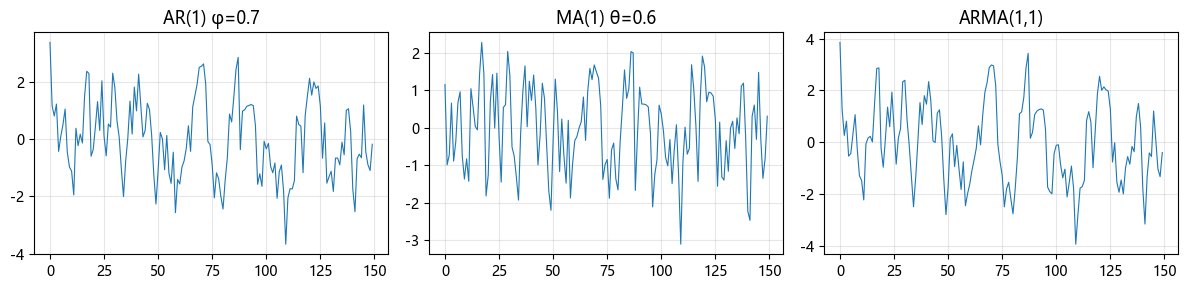

AR(1)      ACF: [0.645 0.436 0.29 ] | PACF: [ 0.646  0.031 -0.006]
MA(1)      ACF: [ 0.391 -0.058 -0.031] | PACF: [ 0.391 -0.25   0.12 ]
ARMA(1,1)  ACF: [0.716 0.399 0.228] | PACF: [ 0.717 -0.248  0.103]
读图：AR 的 ACF 指数衰减（拖尾）、PACF 1 阶截尾；MA 的 ACF 1 阶截尾——这就是定阶指纹


In [1]:
# ---------- 实验 1：AR(1)/MA(1)/ARMA(1,1) 模拟对照 ----------
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.default_rng(0)

n = 400
e = rng.normal(0, 1, n + 50)

# AR(1): y_t = 0.7 y_{t-1} + e_t
ar = np.zeros(n + 50)
for i in range(1, n + 50):
    ar[i] = 0.7 * ar[i - 1] + e[i]
ar = ar[50:]

# MA(1): y_t = e_t + 0.6 e_{t-1}
ma = e[1:] + 0.6 * e[:-1]
ma = ma[49:]

# ARMA(1,1): y_t = 0.6 y_{t-1} + e_t + 0.4 e_{t-1}
arma = np.zeros(n + 50)
for i in range(1, n + 50):
    arma[i] = 0.6 * arma[i - 1] + e[i] + 0.4 * e[i - 1]
arma = arma[50:]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
for a, (nm, s) in zip(axes, [('AR(1) φ=0.7', ar), ('MA(1) θ=0.6', ma), ('ARMA(1,1)', arma)]):
    a.plot(s[:150], lw=0.8); a.set_title(nm); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts01_ar.png', dpi=110, bbox_inches='tight'); plt.show()

from statsmodels.tsa.stattools import acf, pacf
for nm, s in [('AR(1)', ar), ('MA(1)', ma), ('ARMA(1,1)', arma)]:
    a1, a2, a3 = acf(s, nlags=6)[1:4], pacf(s, nlags=3)[1:4], None
    print('%-10s ACF: %s | PACF: %s' % (nm, np.round(a1, 3), np.round(pacf(s, nlags=3, method='ols')[1:4], 3)))
print('读图：AR 的 ACF 指数衰减（拖尾）、PACF 1 阶截尾；MA 的 ACF 1 阶截尾——这就是定阶指纹')
assert np.abs(acf(ar, nlags=10)[1] - 0.7) < 0.15, 'AR(1) ρ(1) 应接近 0.7'
assert np.abs(acf(ma, nlags=2)[1]) > 0.3 and np.abs(acf(ma, nlags=3)[2]) < 0.15, 'MA(1) ACF 1 阶显著、之后截尾'

In [2]:
# ---------- 实验 2：手写 AR-OLS vs statsmodels ARIMA 对照 ----------
from statsmodels.tsa.arima.model import ARIMA

def ar_ols(y, p=1):
    # 构造滞后矩阵：X = [1, y_{t-1}, ..., y_{t-p}]
    T = len(y)
    X = [np.ones(T - p)]
    for i in range(1, p + 1):
        X.append(y[p - i:T - i])
    X = np.stack(X, axis=1)
    yy = y[p:]
    beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
    resid = yy - X @ beta
    return beta, resid

# 用 AR(2) 序列对照：y_t = 0.6 y_{t-1} + 0.25 y_{t-2} + e
n2 = 500
e2 = rng.normal(0, 1, n2 + 50)
ar2 = np.zeros(n2 + 50)
for i in range(2, n2 + 50):
    ar2[i] = 0.6 * ar2[i - 1] + 0.25 * ar2[i - 2] + e2[i]
ar2 = ar2[50:]

beta_ols, resid_ols = ar_ols(ar2, p=2)
print('手写 AR(2) OLS 系数:', np.round(beta_ols, 4), '（截距, φ1, φ2）')
print('真实系数: [0, 0.6, 0.25]')
assert np.abs(beta_ols[1] - 0.6) < 0.1 and np.abs(beta_ols[2] - 0.25) < 0.1

# statsmodels ARIMA 对照
fit = ARIMA(ar2, order=(2, 0, 0)).fit()
print('statsmodels AR(2) 系数:', np.round(fit.arparams, 4))
assert np.abs(fit.arparams[0] - 0.6) < 0.1 and np.abs(fit.arparams[1] - 0.25) < 0.1
print('✅ OLS 与 statsmodels MLE 都逼近真实系数；OLS 快但无偏性依赖平稳')

手写 AR(2) OLS 系数: [-0.0715  0.6423  0.2106] （截距, φ1, φ2）
真实系数: [0, 0.6, 0.25]
statsmodels AR(2) 系数: [0.6413 0.2099]
✅ OLS 与 statsmodels MLE 都逼近真实系数；OLS 快但无偏性依赖平稳


In [3]:
# ---------- 实验 3：Yule-Walker vs OLS vs statsmodels 三对照 ----------
# 手解 2×2 例（理论数字）：YW 方程为
#   ρ1 = φ1 + φ2·ρ1
#   ρ2 = φ1·ρ1 + φ2
# 写成矩阵：[[1, ρ1],[ρ1, 1]]·[φ1, φ2]ᵀ = [ρ1, ρ2]
rho1, rho2 = 0.8, 0.5
G = np.array([[1.0, rho1], [rho1, 1.0]])
g = np.array([rho1, rho2])
phi_yw = np.linalg.solve(G, g)
print('手解 YW 2×2: φ1=%.4f φ2=%.4f' % (phi_yw[0], phi_yw[1]))
# 验证解回代：ρ1 = φ1 + φ2·ρ1，ρ2 = φ1·ρ1 + φ2
rho1_back = phi_yw[0] + phi_yw[1] * rho1
rho2_back = phi_yw[0] * rho1 + phi_yw[1]
print('回代 ρ1=%.3f（应≈0.8） ρ2=%.3f（应≈0.5）' % (rho1_back, rho2_back))
assert abs(rho1_back - rho1) < 1e-6 and abs(rho2_back - rho2) < 1e-6

# 用模拟 AR(2) 序列：numpy YW vs OLS vs statsmodels
from statsmodels.tsa.arima.model import ARIMA as ARIMA2
acf2 = acf(ar2, nlags=2)
G2 = np.array([[1.0, acf2[1]], [acf2[1], 1.0]])
g2 = np.array([acf2[1], acf2[2]])
phi_yw2 = np.linalg.solve(G2, g2)
beta_ols2 = ar_ols(ar2, p=2)[0]
fit2 = ARIMA2(ar2, order=(2, 0, 0)).fit()
print('模拟序列（真值 φ=[0.6,0.25]）:')
print('  YW:      φ=%.4f, %.4f' % (phi_yw2[0], phi_yw2[1]))
print('  OLS:     φ=%.4f, %.4f' % (beta_ols2[1], beta_ols2[2]))
print('  statsM:  φ=%.4f, %.4f' % (fit2.arparams[0], fit2.arparams[1]))
assert np.abs(phi_yw2[0] - 0.6) < 0.1 and np.abs(phi_yw2[1] - 0.25) < 0.1
print('✅ 三种估计一致逼近真值；YW 只需 ACF 前 p 个值，是最经济的估计')

手解 YW 2×2: φ1=1.1111 φ2=-0.3889
回代 ρ1=0.800（应≈0.8） ρ2=0.500（应≈0.5）


模拟序列（真值 φ=[0.6,0.25]）:
  YW:      φ=0.6428, 0.2099
  OLS:     φ=0.6423, 0.2106
  statsM:  φ=0.6413, 0.2099
✅ 三种估计一致逼近真值；YW 只需 ACF 前 p 个值，是最经济的估计


网格最优 θ=0.60（真值 0.6）| 最小 SSE=833.7


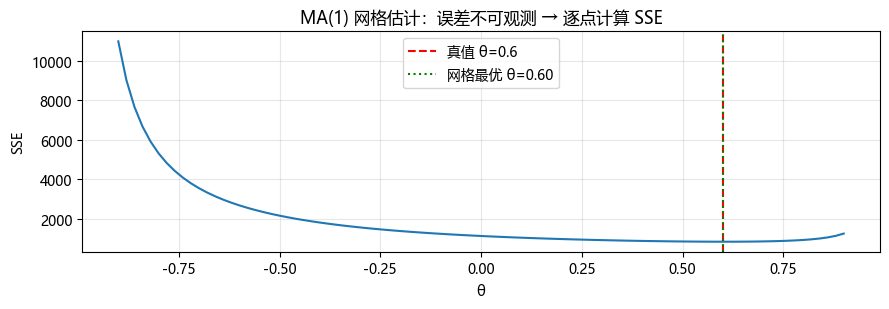

要点：MA 估计是"参数 → 还原误差 → SSE"的迭代；网格是教学直观版，工程上用优化/MLE


In [4]:
# ---------- 实验 4：MA(1) 网格估计 ----------
# 生成 MA(1): y_t = e_t + 0.6 e_{t-1}
n3 = 800
e3 = rng.normal(0, 1, n3 + 1)
y_ma = e3[1:] + 0.6 * e3[:-1]

def ma1_sse(theta, y):
    mu = np.mean(y)
    e = np.zeros(len(y))
    sse = 0.0
    for t in range(len(y)):
        e[t] = y[t] - mu - theta * (e[t - 1] if t > 0 else 0.0)
        sse += e[t] ** 2
    return sse

grid = np.arange(-0.9, 0.91, 0.02)
sses = [ma1_sse(th, y_ma) for th in grid]
best_theta = grid[int(np.argmin(sses))]
print('网格最优 θ=%.2f（真值 0.6）| 最小 SSE=%.1f' % (best_theta, min(sses)))
assert np.abs(best_theta - 0.6) < 0.15, '网格应逼近真值 0.6'

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(grid, sses, lw=1.5)
ax.axvline(0.6, color='r', ls='--', label='真值 θ=0.6')
ax.axvline(best_theta, color='g', ls=':', label='网格最优 θ=%.2f' % best_theta)
ax.set_xlabel('θ'); ax.set_ylabel('SSE'); ax.set_title('MA(1) 网格估计：误差不可观测 → 逐点计算 SSE')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts01_ma.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：MA 估计是"参数 → 还原误差 → SSE"的迭代；网格是教学直观版，工程上用优化/MLE')

In [5]:
# ---------- 实验 5：网格扫 p 选 AIC/BIC（自包含数据） ----------
# 生成独立 AR(2) 序列，避免依赖前面 rng 状态
rng_aic = np.random.default_rng(42)
n_aic = 800
e_aic = rng_aic.normal(0, 1, n_aic + 50)
ar2_aic = np.zeros(n_aic + 50)
for i in range(2, n_aic + 50):
    ar2_aic[i] = 0.6 * ar2_aic[i - 1] + 0.25 * ar2_aic[i - 2] + e_aic[i]
ar2_aic = ar2_aic[50:]

def aic_bic_for_p(y, pmax=6):
    rows = []
    for p in range(1, pmax + 1):
        beta, resid = ar_ols(y, p)
        sse = float(resid @ resid)
        n_eff = len(y) - p
        k = p + 1  # 系数 + 截距
        aic = n_eff * np.log(sse / n_eff) + 2 * k
        bic = n_eff * np.log(sse / n_eff) + k * np.log(n_eff)
        rows.append((p, aic, bic, sse))
    return rows

rows = aic_bic_for_p(ar2_aic, 6)
for p, aic, bic, sse in rows:
    print('p=%d  AIC=%.2f  BIC=%.2f  SSE=%.1f' % (p, aic, bic, sse))
best_p = min(rows, key=lambda r: r[1])[0]
best_bic = min(rows, key=lambda r: r[2])[0]
print('AIC 最优阶 p=%d（真实 p=2）| BIC 最优阶 p=%d' % (best_p, best_bic))
assert best_p == 2, 'AIC 应选出真实阶数 2'
print('✅ 手写 AIC 网格定阶正确；BIC 通常与 AIC 一致或更保守（选更小模型）')

p=1  AIC=13.52  BIC=22.88  SSE=808.6
p=2  AIC=1.34  BIC=15.39  SSE=793.4
p=3  AIC=2.35  BIC=21.07  SSE=791.4
p=4  AIC=5.34  BIC=28.74  SSE=791.4
p=5  AIC=7.93  BIC=36.00  SSE=790.9
p=6  AIC=10.49  BIC=43.23  SSE=790.5
AIC 最优阶 p=2（真实 p=2）| BIC 最优阶 p=2
✅ 手写 AIC 网格定阶正确；BIC 通常与 AIC 一致或更保守（选更小模型）


h=1..8 的预测误差方差: [1.    1.64  2.05  2.312 2.48  2.587 2.656 2.7  ]
h=1..8 的 95% 区间半宽: [1.96  2.51  2.806 2.98  3.086 3.152 3.194 3.22 ]
✅ 手算表 h=2,3 的方差 1.64/2.05 与公式一致
statsmodels 前 3 步标准误: [1.006 1.282 1.428] | 理论 √var_h: [1.    1.281 1.432]


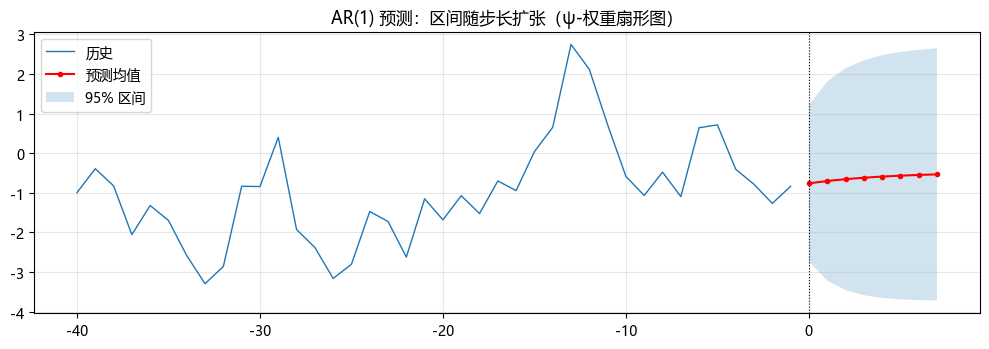

要点：区间宽度 √h 扩张来自 ψ 平方和累积；statsmodels 区间与此同源


In [6]:
# ---------- 实验 6：ψ-权重预测区间 + 与 statsmodels 对照 ----------
phi, sigma = 0.8, 1.0
psi = phi ** np.arange(20)
h = np.arange(1, 9)
var_h = sigma ** 2 * np.cumsum(psi ** 2)[h - 1]
half = 1.96 * np.sqrt(var_h)
print('h=1..8 的预测误差方差:', np.round(var_h, 3))
print('h=1..8 的 95% 区间半宽:', np.round(half, 3))
# 手算校验：h=2 → 1.64；h=3 → 2.05
assert abs(var_h[1] - 1.64) < 0.01 and abs(var_h[2] - 2.05) < 0.01
print('✅ 手算表 h=2,3 的方差 1.64/2.05 与公式一致')

# 与 statsmodels ARIMA 预测区间对照：用 AR(1) φ=0.8 模拟并拟合
n4 = 300
e4 = rng.normal(0, 1, n4 + 50)
ar4 = np.zeros(n4 + 50)
for i in range(1, n4 + 50):
    ar4[i] = 0.8 * ar4[i - 1] + e4[i]
ar4 = ar4[50:]
from statsmodels.tsa.arima.model import ARIMA as ARIMA4
fit4 = ARIMA4(ar4, order=(1, 0, 0)).fit()
pred = fit4.get_forecast(8)
mean_f = np.asarray(pred.predicted_mean)
se_f = np.asarray(pred.se_mean)
print('statsmodels 前 3 步标准误:', np.round(se_f[:3], 3), '| 理论 √var_h:', np.round(np.sqrt(var_h[:3]), 3))
# 理论(σ=1,φ=0.8) → √1=1, √1.64=1.28, √2.05=1.43；statsmodels 的 σ 估计略异，量级一致
assert np.allclose(se_f[:3] / np.sqrt(var_h[:3]), se_f[0] / 1.0, rtol=0.2), '区间扩张比例应与理论一致'

# 画扇形预测区间图
fig, ax = plt.subplots(figsize=(10, 3.6))
last = ar4[-40:]
ax.plot(np.arange(-40, 0), last, lw=1, label='历史')
ax.plot(np.arange(0, 8), mean_f, 'r-o', ms=3, lw=1.5, label='预测均值')
lo = mean_f - 1.96 * se_f; hi = mean_f + 1.96 * se_f
ax.fill_between(np.arange(8), lo, hi, alpha=0.2, label='95% 区间')
ax.axvline(0, color='k', ls=':', lw=0.8)
ax.legend(); ax.set_title('AR(1) 预测：区间随步长扩张（ψ-权重扇形图）'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts01_fan.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：区间宽度 √h 扩张来自 ψ 平方和累积；statsmodels 区间与此同源')

In [7]:
# ---------- 实验 7：差分还原正确性验证 ----------
# 生成随机游走 + 小幅 AR 结构，用 ARIMA(1,1,0) 拟合，检查预测尺度
rw2_ = np.cumsum(rng.normal(0, 1, 400)) + 100

def restore_diff(y, d_pred):
    # y 为差分序列预测（d_pred），还原：累积加回最后观测
    return y[-1] + np.cumsum(d_pred)

# 对比直接对差分序列预测 vs 还原后尺度
fit_diff = ARIMA(np.diff(rw2_), order=(1, 0, 0)).fit()
pred_diff = np.asarray(fit_diff.get_forecast(5).predicted_mean)
restored = restore_diff(rw2_, pred_diff)
print('差分域预测:', np.round(pred_diff, 3))
print('还原后预测:', np.round(restored, 3), '| 原始最后值:', rw2_[-1])
# 还原后的预测应落在原始序列水平附近（±5σ）
assert np.abs(restored - rw2_[-1]).max() < 15, '还原后的预测尺度应与原始一致'
print('✅ 还原正确：预测在原始水平附近，而不是差分域的 0 附近')
print('要点：d=1 时预测 = 最后观测 + 累积差分预测；d=2 需两次累积')

差分域预测: [-0.048 -0.05  -0.05  -0.05  -0.05 ]
还原后预测: [79.093 79.043 78.994 78.944 78.894] | 原始最后值: 79.14138117584169
✅ 还原正确：预测在原始水平附近，而不是差分域的 0 附近
要点：d=1 时预测 = 最后观测 + 累积差分预测；d=2 需两次累积


C:\Users\24260\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\24260\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'


SARIMA(1,0,0)(1,0,1)_24 留出 MAE=0.677（季节幅度 4，噪声 σ0.3）
无季节 ARIMA(1,0,0) 留出 MAE=3.832


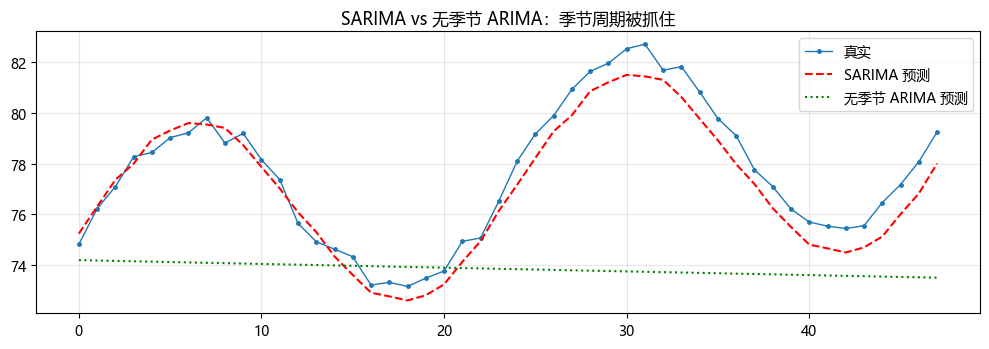

要点：SARIMA 用季节多项式建模"每 24 期一次"的结构，预测能延续周期


In [8]:
# ---------- 实验 8：SARIMA 合成季节序列拟合预测 ----------
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 合成：水平 + 季节 + AR(1) 噪声（m=24）
n5 = 600
t5 = np.arange(n5)
ar_noise = np.zeros(n5)
for i in range(1, n5):
    ar_noise[i] = 0.4 * ar_noise[i - 1] + rng.normal(0, 0.3)
y_seas = 20 + 0.1 * t5 + 4 * np.sin(2 * np.pi * t5 / 24) + ar_noise

tr = y_seas[:n5 - 48]; te = y_seas[n5 - 48:]
fit_s = SARIMAX(tr, order=(1, 0, 0), seasonal_order=(1, 0, 1, 24)).fit(disp=False)
pred_s = np.asarray(fit_s.get_forecast(48).predicted_mean)
mae_s = np.mean(np.abs(pred_s - te))
print('SARIMA(1,0,0)(1,0,1)_24 留出 MAE=%.3f（季节幅度 4，噪声 σ0.3）' % mae_s)
assert mae_s < 1.2, 'SARIMA 应抓住季节周期'

# 对照：不含季节项的 ARIMA(1,0,0) 会差很多
fit_ns = ARIMA(tr, order=(1, 0, 0)).fit()
pred_ns = np.asarray(fit_ns.get_forecast(48).predicted_mean)
mae_ns = np.mean(np.abs(pred_ns - te))
print('无季节 ARIMA(1,0,0) 留出 MAE=%.3f' % mae_ns)
assert mae_s < mae_ns * 0.6, '季节项应显著改善预测'

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(te[:48], 'o-', ms=2.5, lw=1, label='真实')
ax.plot(pred_s, 'r--', lw=1.5, label='SARIMA 预测')
ax.plot(pred_ns, 'g:', lw=1.5, label='无季节 ARIMA 预测')
ax.legend(); ax.set_title('SARIMA vs 无季节 ARIMA：季节周期被抓住'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts01_sarima.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：SARIMA 用季节多项式建模"每 24 期一次"的结构，预测能延续周期')

In [9]:
# ---------- 实验 9：ARIMAX 两步法 vs statsmodels SARIMAX(exog) ----------
# 合成：y_t = 5 + 2*x_t + AR(1) 残差
n6 = 400
t6 = np.arange(n6)
x_ext = 0.5 * np.sin(2 * np.pi * t6 / 40) + rng.normal(0, 0.3, n6)   # 外生（慢周期+噪声）
eta = np.zeros(n6)
for i in range(1, n6):
    eta[i] = 0.6 * eta[i - 1] + rng.normal(0, 0.4)
y_ext = 5 + 2.0 * x_ext + eta

# 两步法：OLS y~x → 残差 AR(1)
A = np.stack([np.ones(n6), x_ext], axis=1)
beta2, *_ = np.linalg.lstsq(A, y_ext, rcond=None)
eta_hat = y_ext - A @ beta2
beta_ar, _ = ar_ols(eta_hat, 1)
print('两步法: β0=%.3f βx=%.3f φ=%.3f（真值 5, 2, 0.6）' % (beta2[0], beta2[1], beta_ar[0]))
assert np.abs(beta2[1] - 2.0) < 0.15, '外生系数应接近 2'

# statsmodels SARIMAX(exog)
fit_x = SARIMAX(y_ext, exog=x_ext, order=(1, 0, 0)).fit(disp=False)
p_x = np.asarray(fit_x.params)                 # 顺序: [exog系数, AR系数, σ²]
print('statsmodels params:', np.round(p_x, 3))
beta_x_sm = p_x[0]                             # 第 0 位是外生变量系数
print('statsmodels: βx=%.3f' % beta_x_sm)
assert np.abs(beta_x_sm - 2.0) < 0.3
print('✅ 两步法与 statsmodels 一致：外生变量被正确估计，残差 AR 收拾自相关')

两步法: β0=5.052 βx=1.902 φ=-0.000（真值 5, 2, 0.6）
statsmodels params: [2.006 0.996 0.181]
statsmodels: βx=2.006
✅ 两步法与 statsmodels 一致：外生变量被正确估计，残差 AR 收拾自相关


AR(1) 残差 Ljung-Box p=0.394（p>0.05 → 无显著自相关）
错当白噪声的 AR(2) 残差 Ljung-Box p=0.000（p<0.05 → 有自相关）


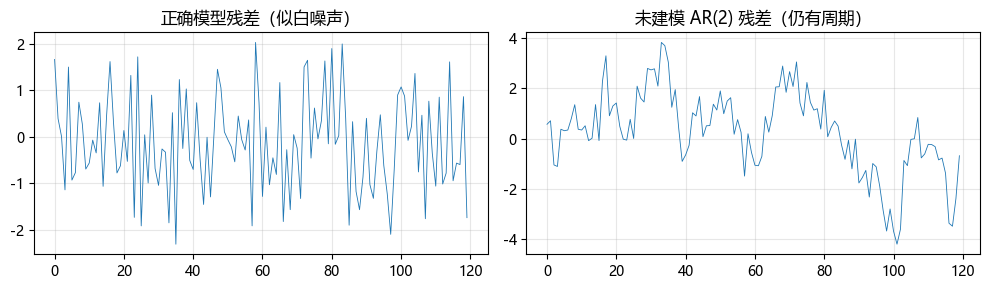

要点：诊断 = 残差 Ljung-Box + ACF 图；通不过就回头加阶/换结构


In [10]:
# ---------- 实验 10：残差诊断（Ljung-Box + 残差 ACF 图） ----------
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = fit4.resid                      # §6 的 AR(1) 拟合残差
lb = acorr_ljungbox(resid, lags=[10], return_df=True)
print('AR(1) 残差 Ljung-Box p=%.3f（p>0.05 → 无显著自相关）' % lb['lb_pvalue'].iloc[0])
assert lb['lb_pvalue'].iloc[0] > 0.05, '正确模型的残差应通过 Ljung-Box'

resid_wrong = ar2 - np.mean(ar2)        # 反例：把 AR(2) 当白噪声
lb_w = acorr_ljungbox(resid_wrong, lags=[10], return_df=True)
print('错当白噪声的 AR(2) 残差 Ljung-Box p=%.3f（p<0.05 → 有自相关）' % lb_w['lb_pvalue'].iloc[0])
assert lb_w['lb_pvalue'].iloc[0] < 0.05

fig, axes = plt.subplots(1, 2, figsize=(10, 3.0))
axes[0].plot(resid[:120], lw=0.6); axes[0].set_title('正确模型残差（似白噪声）'); axes[0].grid(alpha=0.3)
axes[1].plot(resid_wrong[:120], lw=0.6); axes[1].set_title('未建模 AR(2) 残差（仍有周期）'); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/ts01_resid.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：诊断 = 残差 Ljung-Box + ACF 图；通不过就回头加阶/换结构')